# Validación de supuestos y otras pruebas


## 1. Datos y partición

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.model_selection import RepeatedStratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures, SplineTransformer, StandardScaler

sns.set_style("darkgrid")
warnings.filterwarnings("ignore")

RANDOM_STATE = 7
FIG_DIR = Path("..") / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

Cargamos los datos igual que en el 07: solo adultos, porque ya vimos en el EDA que los niños casi no tienen casos.

In [2]:
RUTA = Path("..") / "data" / "raw" / "NHANES_consolidado.csv"
df_nhanes = pd.read_csv(RUTA)
adultos = df_nhanes[df_nhanes["Edad"] >= 18].copy()
print("Total de filas:", len(df_nhanes))
print("Adultos:", len(adultos))
print("Positivos:", adultos["Diabetes"].sum(), "->", round(adultos["Diabetes"].mean() * 100, 1), "%")
adultos.head()

Total de filas: 9763
Adultos: 6110
Positivos: 902 -> 14.8 %


,Diabetes,Edad,Genero,Raza_Etnia,Ingreso_Hogar,Ingreso_Familia,IMC,Cintura_cm,Presion_Sistolica,Presion_Diastolica,Colesterol_Total,Colesterol_HDL
0,1,69.0,1.0,4.0,4.0,4.0,26.7,100.0,122.0,72.0,167.0,65.0
1,1,54.0,1.0,3.0,7.0,7.0,28.6,107.6,156.0,62.0,170.0,50.0
2,1,72.0,1.0,3.0,10.0,10.0,28.9,109.2,140.0,90.0,126.0,60.0
4,0,73.0,2.0,3.0,15.0,15.0,19.7,NaN,136.0,86.0,201.0,85.0
5,0,56.0,1.0,1.0,9.0,9.0,41.7,123.1,160.0,84.0,226.0,38.0


In [3]:
# diastólica casi 0 pasa a nulo y género a 0/1 (igual que el cuaderno 07)
print("Diastólicas en ~0:", (adultos["Presion_Diastolica"] < 1).sum())
adultos.loc[adultos["Presion_Diastolica"] < 1, "Presion_Diastolica"] = np.nan
adultos["Mujer"] = (adultos["Genero"] == 2).astype(int)
print(adultos["Mujer"].value_counts())

Diastólicas en ~0: 29
Mujer
1    3194
0    2916
Name: count, dtype: int64


In [4]:
VARS_SIN_LAB = ["Edad", "Mujer", "IMC", "Cintura_cm", "Presion_Sistolica", "Presion_Diastolica"]
VARS_CON_LAB = VARS_SIN_LAB + ["Colesterol_Total", "Colesterol_HDL"]
ESCENARIOS = {"Sin laboratorio": VARS_SIN_LAB, "Con laboratorio": VARS_CON_LAB}

X = adultos[VARS_CON_LAB]
y = adultos["Diabetes"]
print(X.shape, y.shape)

(6110, 8) (6110,)


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
print("Entrenamiento:", X_train.shape, ", positivos:", y_train.sum(), ", tasa:", round(y_train.mean() * 100, 1), "%")
print("Prueba:", X_test.shape, ", positivos:", y_test.sum(), ", tasa:", round(y_test.mean() * 100, 1), "%")

# copia del entrenamiento con nulos rellenados con la mediana (solo para las pruebas)
X_imp = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(X_train),
                     columns=VARS_CON_LAB, index=X_train.index)
print("Nulos antes:", X_train.isna().sum().sum(), "| después:", X_imp.isna().sum().sum())
X_imp.head()

Entrenamiento: (4888, 8) , positivos: 722 , tasa: 14.8 %
Prueba: (1222, 8) , positivos: 180 , tasa: 14.7 %
Nulos antes: 2518 | después: 0


,Edad,Mujer,IMC,Cintura_cm,Presion_Sistolica,Presion_Diastolica,Colesterol_Total,Colesterol_HDL
5001,80.0,1.0,24.6,89.5,162.0,74.0,164.0,60.0
3478,80.0,1.0,31.6,101.8,138.0,70.0,256.0,42.0
5624,56.0,0.0,29.2,100.3,128.0,62.0,245.0,44.0
7699,40.0,1.0,33.7,107.9,106.0,66.0,174.0,61.0
2362,60.0,0.0,29.4,101.6,164.0,76.0,124.0,46.0


In [6]:
def recall_at_k(y_true, y_score, k=0.40):
    y_true = np.asarray(y_true)
    y_score = np.asarray(y_score)
    n_tamizar = int(np.ceil(k * len(y_true)))
    orden = np.argsort(-y_score, kind="stable")
    return y_true[orden[:n_tamizar]].sum() / y_true.sum()

def pipeline_logistica(class_weight="balanced", C=1.0):
    return Pipeline([
        ("imputar", SimpleImputer(strategy="median")),
        ("escalar", StandardScaler()),
        ("modelo", LogisticRegression(class_weight=class_weight, C=C, max_iter=1000)),
    ])

def pipeline_splines(columnas, vars_spline=("Edad", "Cintura_cm"), interaccion=False, C=1.0, n_knots=5):
    vars_spline = list(vars_spline)
    vars_lineales = [c for c in columnas if c not in vars_spline]
    transformaciones = [
        ("splines", Pipeline([("imputar", SimpleImputer(strategy="median")),
                              ("spline", SplineTransformer(n_knots=n_knots, degree=3))]), vars_spline),
        ("lineales", Pipeline([("imputar", SimpleImputer(strategy="median")),
                               ("escalar", StandardScaler())]), vars_lineales),
    ]
    if interaccion:
        transformaciones.append(("interaccion", Pipeline([
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
            ("producto", PolynomialFeatures(degree=2, interaction_only=True, include_bias=False)),
        ]), ["Edad", "Cintura_cm"]))
    return Pipeline([("preparar", ColumnTransformer(transformaciones)),
                     ("modelo", LogisticRegression(class_weight="balanced", C=C, max_iter=2000))])

# prueba rápida de la métrica: la edad sola debe dar 72.3 % como en el EDA
print("Solo edad:", round(recall_at_k(y, X["Edad"]) * 100, 1), "%")

Solo edad: 72.3 %


## 2. Supuestos

### 2.1. Suficiencia de casos

La regresión logística necesita como mínimo unos 10 positivos por cada parámetro que estima. Entonces contamos cuántos parámetros usa cada modelo ajustándolo.

In [7]:
eventos = int(y_train.sum())
print("Positivos en entrenamiento:", eventos)

filas = []
for escenario, cols in ESCENARIOS.items():
    modelos = {"Logística": pipeline_logistica(),
               "Splines + interacción": pipeline_splines(cols, interaccion=True)}
    for nombre, modelo in modelos.items():
        modelo.fit(X_train[cols], y_train)
        n_param = modelo.named_steps["modelo"].coef_.shape[1]
        filas.append({"escenario": escenario, "modelo": nombre, "parametros": n_param,
                      "positivos_por_parametro": round(eventos / n_param, 1)})
tabla_epv = pd.DataFrame(filas)
tabla_epv["cumple_10"] = tabla_epv["positivos_por_parametro"] >= 10
tabla_epv

Positivos en entrenamiento: 722


,escenario,modelo,parametros,positivos_por_parametro,cumple_10
0,Sin laboratorio,Logística,6,120.3,True
1,Sin laboratorio,Splines + interacción,21,34.4,True
2,Con laboratorio,Logística,8,90.2,True
3,Con laboratorio,Splines + interacción,23,31.4,True


Todos cumplen. Los que más parámetros gastan son los splines con interacción (21 y 23) y aun así les sobran casos: tienen más de 30 positivos por parámetro.

### 2.2. Independencia

Cada fila tiene que ser una persona distinta. Buscamos filas repetidas y gente que no tiene ninguna medida.

In [8]:
repetidas = adultos[adultos.duplicated(keep=False)]
print("Filas idénticas entre los adultos:", len(repetidas))
repetidas[["Edad", "Mujer"] + VARS_CON_LAB[2:]]

Filas idénticas entre los adultos: 4


,Edad,Mujer,IMC,Cintura_cm,Presion_Sistolica,Presion_Diastolica,Colesterol_Total,Colesterol_HDL
2542,80.0,0,NaN,NaN,NaN,NaN,NaN,NaN
2998,80.0,1,NaN,NaN,NaN,NaN,NaN,NaN
6115,80.0,1,NaN,NaN,NaN,NaN,NaN,NaN
7948,80.0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [9]:
for escenario, cols in ESCENARIOS.items():
    medidas = [v for v in cols if v not in ("Edad", "Mujer")]
    sin_medidas = adultos[medidas].isna().all(axis=1)
    print(escenario, "-> adultos sin ninguna medida:", int(sin_medidas.sum()), "(", round(sin_medidas.mean() * 100, 1), "%)")

Sin laboratorio -> adultos sin ninguna medida: 207 ( 3.4 %)
Con laboratorio -> adultos sin ninguna medida: 193 ( 3.2 %)


Las 4 filas repetidas no son personas duplicadas: son adultos de 80 años que no tienen ninguna medida (todo nulo) y por casualidad coinciden en edad y género. Sin laboratorio hay 207 adultos (3,4 %) sin ninguna medida y con laboratorio 193 (3,2 %); a ellos el modelo solo les ve la edad y el género

### 2.3. Datos faltantes


In [10]:
nulos = pd.DataFrame({"n_nulos": X_train.isna().sum(),
                      "pct_nulos": (X_train.isna().mean() * 100).round(1)})
print(nulos[nulos["n_nulos"] > 0])
for escenario, cols in ESCENARIOS.items():
    completos = X_train[cols].notna().all(axis=1)
    print(f"{escenario}: {completos.sum()} casos completos de {len(X_train)} ({round(completos.mean() * 100, 1)} %)")

                    n_nulos  pct_nulos
IMC                     212        4.3
Cintura_cm              425        8.7
Presion_Sistolica       555       11.4
Presion_Diastolica      580       11.9
Colesterol_Total        373        7.6
Colesterol_HDL          373        7.6
Sin laboratorio: 4087 casos completos de 4888 (83.6 %)
Con laboratorio: 3922 casos completos de 4888 (80.2 %)


In [11]:
# ¿quienes no tienen el dato se parecen al resto en edad y en porcentaje de casos?
filas = []
for v in VARS_CON_LAB:
    falta = X_train[v].isna()
    if falta.sum() == 0:
        continue
    p_edad = stats.mannwhitneyu(X_train.loc[falta, "Edad"], X_train.loc[~falta, "Edad"]).pvalue
    p_casos = stats.chi2_contingency(pd.crosstab(falta, y_train))[1]
    filas.append({"variable": v,
                  "edad_media_con_dato": round(X_train.loc[~falta, "Edad"].mean(), 1),
                  "edad_media_sin_dato": round(X_train.loc[falta, "Edad"].mean(), 1),
                  "p_edad": round(p_edad, 4),
                  "pct_casos_con_dato": round(y_train[~falta].mean() * 100, 1),
                  "pct_casos_sin_dato": round(y_train[falta].mean() * 100, 1),
                  "p_casos": round(p_casos, 3)})
pd.DataFrame(filas).set_index("variable")

,edad_media_con_dato,edad_media_sin_dato,p_edad,pct_casos_con_dato,pct_casos_sin_dato,p_casos
variable,,,,,,
IMC,47.3,48.8,0.3308,14.9,12.7,0.450
Cintura_cm,47.0,51.9,0.0000,14.6,16.7,0.269
Presion_Sistolica,47.1,49.5,0.0052,14.6,16.2,0.339
Presion_Diastolica,47.1,49.9,0.0007,14.5,16.9,0.140
Colesterol_Total,47.5,45.7,0.0520,14.9,13.7,0.585
Colesterol_HDL,47.5,45.7,0.0520,14.9,13.7,0.585


Los que no tienen cintura o presión son un poco mayores (52 contra 47 años en la cintura: unos 49,5 a 50 contra 47 en las presiones) y esa diferencia sí es clara (p menor a 0,01). El porcentaje de casos es parecido con y sin dato, y en IMC y colesterol no hay diferencias claras. O sea: lo que falta depende de la edad (que ya está en el modelo), pero no del diagnóstico.

Con casos completos nos quedaría el 83,6 % del entrenamiento sin laboratorio y el 80,2 % con laboratorio. Como rellenamos dentro del pipeline, no se pierde ninguna fila.

In [12]:
opciones = {
    "mediana": SimpleImputer(strategy="median"),
    "mediana + indicador": SimpleImputer(strategy="median", add_indicator=True),
    "iterativa": IterativeImputer(random_state=RANDOM_STATE, max_iter=10),
    "vecinos (k=15)": KNNImputer(n_neighbors=15),
}
cv_rep = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)

filas = []
for escenario, cols in ESCENARIOS.items():
    for nombre, imputador in opciones.items():
        modelo = Pipeline([("imputar", clone(imputador)), ("escalar", StandardScaler()),
                           ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000))])
        r = []
        for tr, va in cv_rep.split(X_train[cols], y_train):
            m = clone(modelo).fit(X_train[cols].iloc[tr], y_train.iloc[tr])
            r.append(recall_at_k(y_train.iloc[va], m.predict_proba(X_train[cols].iloc[va])[:, 1]))
        filas.append({"escenario": escenario, "imputación": nombre,
                      "recall_40_media": round(np.mean(r), 4), "desv": round(np.std(r), 4)})
pd.DataFrame(filas).pivot(index="imputación", columns="escenario", values="recall_40_media")

escenario,Con laboratorio,Sin laboratorio
imputación,,
iterativa,0.7969,0.7788
mediana,0.7969,0.7798
mediana + indicador,0.7950,0.7788
vecinos (k=15),0.7941,0.7770


Casi no cambia: sin laboratorio el recall queda entre 0,777 y 0,780, y con laboratorio entre 0,794 y 0,797. Esa diferencia es mucho menor que lo que varía de una partición a otra (unos 0,03). Nos quedamos con la mediana, que es la más sencilla.

### 2.4. Multicolinealidad

Miramos qué tanto se parecen las variables entre sí (correlación y VIF). Un VIF mayor a 5 es alerta y mayor a 10 ya es problema.

In [13]:
X_imp[VARS_CON_LAB].corr().round(2)

,Edad,Mujer,IMC,Cintura_cm,Presion_Sistolica,Presion_Diastolica,Colesterol_Total,Colesterol_HDL
Edad,1.00,0.01,0.07,0.22,0.43,0.07,0.11,0.08
Mujer,0.01,1.00,0.09,-0.07,-0.11,-0.10,0.09,0.27
IMC,0.07,0.09,1.00,0.86,0.11,0.12,0.06,-0.25
Cintura_cm,0.22,-0.07,0.86,1.00,0.18,0.14,0.06,-0.31
Presion_Sistolica,0.43,-0.11,0.11,0.18,1.00,0.39,0.11,-0.02
Presion_Diastolica,0.07,-0.10,0.12,0.14,0.39,1.00,0.17,-0.05
Colesterol_Total,0.11,0.09,0.06,0.06,0.11,0.17,1.00,0.18
Colesterol_HDL,0.08,0.27,-0.25,-0.31,-0.02,-0.05,0.18,1.00


In [14]:
resultado_vif = {}
for escenario, cols in ESCENARIOS.items():
    vif = {}
    for v in cols:
        otras = [o for o in cols if o != v]
        r2 = LinearRegression().fit(X_imp[otras], X_imp[v]).score(X_imp[otras], X_imp[v])
        vif[v] = 1 / (1 - r2)
    resultado_vif[escenario] = pd.Series(vif)
pd.DataFrame(resultado_vif).round(2)

,Sin laboratorio,Con laboratorio
Cintura_cm,4.52,4.64
Colesterol_HDL,NaN,1.26
Colesterol_Total,NaN,1.09
Edad,1.36,1.39
IMC,4.35,4.35
Mujer,1.12,1.20
Presion_Diastolica,1.22,1.24
Presion_Sistolica,1.49,1.49


Todos los VIF están por debajo de 5 en los dos escenarios. Los más altos son cintura (4,5 y 4,6) e IMC (4,4), que ya sabíamos que se parecen mucho (correlación de 0,86). 

### 2.5. Validacion de tipo de realcion


In [15]:
resultado_bt = {}
for escenario, cols in ESCENARIOS.items():
    continuas = [v for v in cols if v != "Mujer"]
    Xbt = X_imp[cols].copy()
    for v in continuas:
        Xbt[v + "_xlnx"] = Xbt[v] * np.log(Xbt[v])
    ajuste = sm.Logit(y_train, sm.add_constant(Xbt)).fit(disp=0)
    resultado_bt[escenario] = pd.Series(ajuste.pvalues[[v + "_xlnx" for v in continuas]].values, index=continuas)

tabla_bt = pd.DataFrame(resultado_bt)
print("p-valores de Box-Tidwell (lineal si p > 0.05 / n. de variables):")
tabla_bt.round(4)

p-valores de Box-Tidwell (lineal si p > 0.05 / n. de variables):


,Sin laboratorio,Con laboratorio
Cintura_cm,0.0872,0.1444
Colesterol_HDL,NaN,0.3385
Colesterol_Total,NaN,0.0009
Edad,0.0000,0.0000
IMC,0.6199,0.7596
Presion_Diastolica,0.6170,0.3566
Presion_Sistolica,0.1621,0.1061


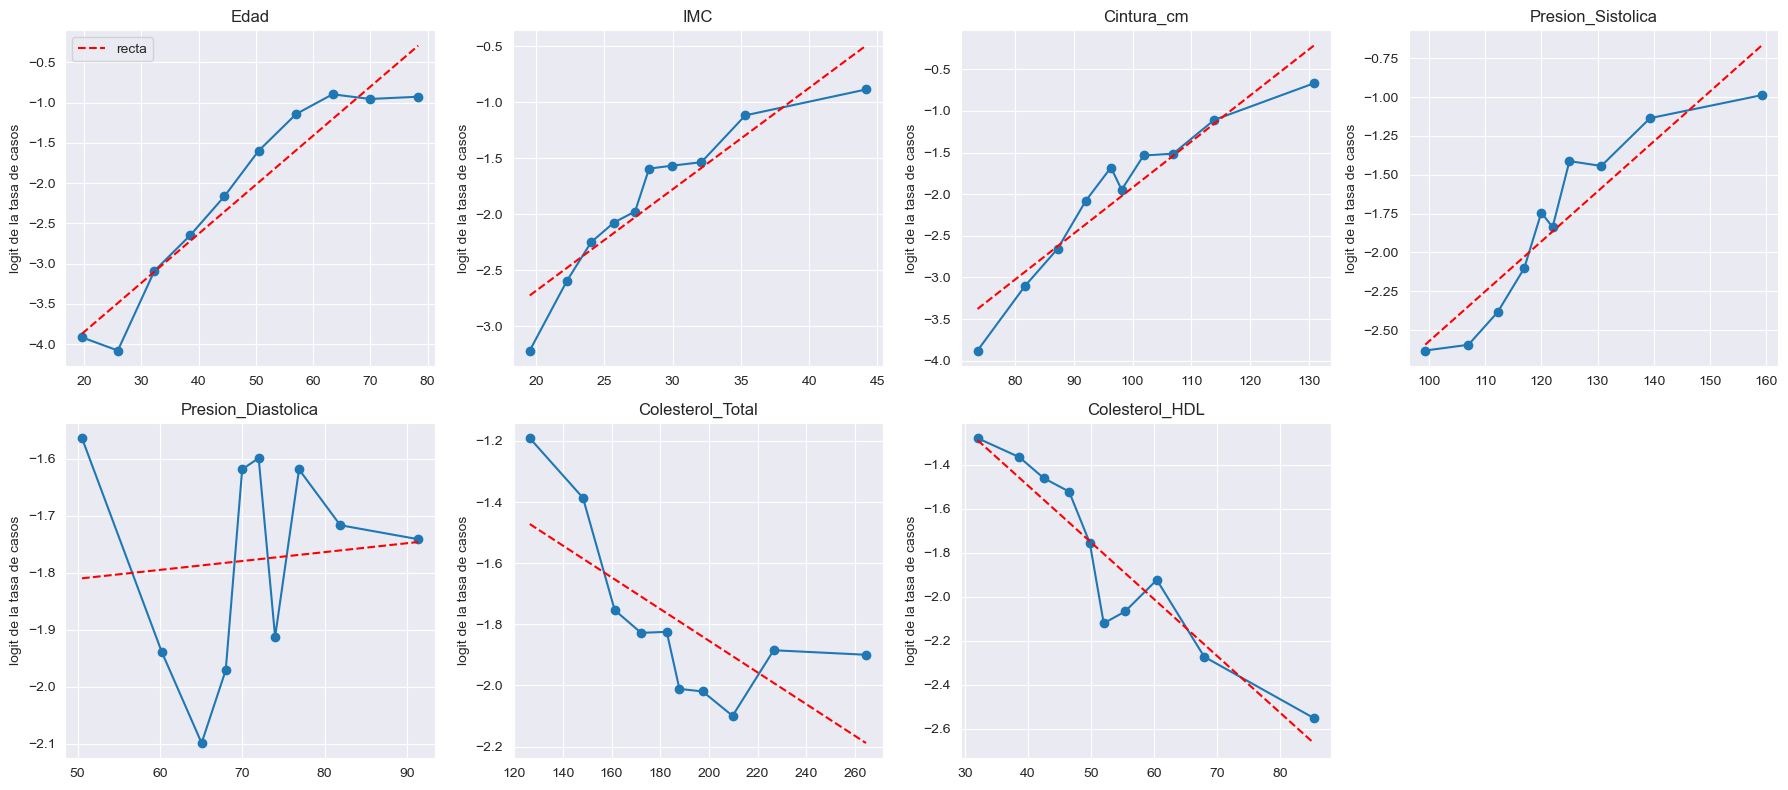

In [16]:
CONTINUAS = [v for v in VARS_CON_LAB if v != "Mujer"]
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, v in zip(axes.flatten(), CONTINUAS):
    tramos = pd.qcut(X_imp[v], 10, duplicates="drop")
    g = pd.DataFrame({"x": X_imp[v], "y": y_train}).groupby(tramos, observed=True).agg(x=("x", "mean"), p=("y", "mean"))
    p = g["p"].clip(0.005, 0.995)
    logit = np.log(p / (1 - p))
    ax.plot(g["x"], logit, "o-")
    pendiente, origen = np.polyfit(g["x"], logit, 1)
    ax.plot(g["x"], pendiente * g["x"] + origen, "--", color="red", label="recta")
    ax.set_title(v)
    ax.set_ylabel("logit de la tasa de casos")
axes.flatten()[-1].axis("off")
axes.flatten()[0].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "supuestos_escenarios_linealidad.png", dpi=150)
plt.show()

### 2.6. Casos atipicos

Calculamos la distancia de Cook (con 4/n como referencia) en cada escenario y vemos si el recall en prueba cambia al quitar los casos que pasan ese límite.

In [17]:
filas = []
for escenario, cols in ESCENARIOS.items():
    glm = sm.GLM(y_train, sm.add_constant(X_imp[cols]), family=sm.families.Binomial()).fit()
    cook = glm.get_influence().cooks_distance[0]
    influyentes = cook > 4 / len(X_imp)

    con_todos = pipeline_logistica().fit(X_train[cols], y_train)
    sin_infl = pipeline_logistica().fit(X_train[cols][~influyentes], y_train[~influyentes])
    filas.append({"escenario": escenario, "cook_maxima": round(cook.max(), 4),
                  "sobre_4/n": int(influyentes.sum()), "pct": round(influyentes.mean() * 100, 1),
                  "recall_prueba_con_todos": round(recall_at_k(y_test, con_todos.predict_proba(X_test[cols])[:, 1]), 3),
                  "recall_prueba_sin_influyentes": round(recall_at_k(y_test, sin_infl.predict_proba(X_test[cols])[:, 1]), 3)})
pd.DataFrame(filas).set_index("escenario")

,cook_maxima,sobre_4/n,pct,recall_prueba_con_todos,recall_prueba_sin_influyentes
escenario,,,,,
Sin laboratorio,0.0291,367,7.5,0.750,0.756
Con laboratorio,0.0299,372,7.6,0.789,0.800


### 2.7. Fuga de información

Revisamos que ninguna variable del cuestionario de diabetes se haya colado en el modelo y que la partición esté bien hecha.

In [18]:
for escenario, cols in ESCENARIOS.items():
    print(escenario, "-> variables DIQ:", [v for v in cols if v.startswith("DIQ")],
          "| glucosa o insulina:", any("glu" in v.lower() or "insul" in v.lower() for v in cols))
print("Tasa de positivos en train y test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

Sin laboratorio -> variables DIQ: [] | glucosa o insulina: False
Con laboratorio -> variables DIQ: [] | glucosa o insulina: False
Tasa de positivos en train y test: 0.148 0.147


## 3. Test multisemillas (20 semillas)

In [19]:
MODELOS = {
    "Solo edad": (["Edad"], lambda: LogisticRegression()),
    "Logística sin lab": (VARS_SIN_LAB, lambda: pipeline_logistica()),
    "Logística con lab": (VARS_CON_LAB, lambda: pipeline_logistica()),
    "Splines + interacción sin lab": (VARS_SIN_LAB, lambda: pipeline_splines(VARS_SIN_LAB, interaccion=True, C=10, n_knots=4)),
    "Splines + interacción con lab": (VARS_CON_LAB, lambda: pipeline_splines(VARS_CON_LAB, interaccion=True, C=10, n_knots=4)),
}
print(list(MODELOS))

['Solo edad', 'Logística sin lab', 'Logística con lab', 'Splines + interacción sin lab', 'Splines + interacción con lab']


In [20]:
# resultado de cada modelo en la partición base (semilla 7)
filas = []
for nombre, (cols, fabrica) in MODELOS.items():
    m = fabrica().fit(X_train[cols], y_train)
    p = m.predict_proba(X_test[cols])[:, 1]
    filas.append({"modelo": nombre, "recall_40": recall_at_k(y_test, p),
                  "roc_auc": roc_auc_score(y_test, p), "pr_auc": average_precision_score(y_test, p)})
base = pd.DataFrame(filas).set_index("modelo")
base.round(3)

,recall_40,roc_auc,pr_auc
modelo,,,
Solo edad,0.728,0.747,0.265
Logística sin lab,0.750,0.781,0.340
Logística con lab,0.789,0.796,0.388
Splines + interacción sin lab,0.761,0.790,0.366
Splines + interacción con lab,0.767,0.805,0.432


In [21]:
SEMILLAS = [s for s in range(1, 22) if s != RANDOM_STATE]
print(len(SEMILLAS), "semillas:", SEMILLAS)

filas = []
for semilla in SEMILLAS:
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.20, stratify=y, random_state=semilla)
    for nombre, (cols, fabrica) in MODELOS.items():
        m = fabrica().fit(Xtr[cols], ytr)
        p = m.predict_proba(Xte[cols])[:, 1]
        filas.append({"semilla": semilla, "modelo": nombre, "recall_40": recall_at_k(yte, p),
                      "roc_auc": roc_auc_score(yte, p), "pr_auc": average_precision_score(yte, p)})
semillas = pd.DataFrame(filas)
print(semillas.shape)
semillas.head()

20 semillas: [1, 2, 3, 4, 5, 6, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21]


(100, 5)


,semilla,modelo,recall_40,roc_auc,pr_auc
0,1,Solo edad,0.727778,0.731347,0.261706
1,1,Logística sin lab,0.761111,0.775752,0.319212
2,1,Logística con lab,0.794444,0.789403,0.359113
3,1,Splines + interacción sin lab,0.788889,0.782853,0.338180
4,1,Splines + interacción con lab,0.800000,0.799251,0.386798


In [22]:
resumen = semillas.groupby("modelo", sort=False).agg(
    recall_media=("recall_40", "mean"), recall_desv=("recall_40", "std"),
    recall_min=("recall_40", "min"), recall_max=("recall_40", "max"),
    semillas_sobre_meta=("recall_40", lambda s: int((s >= 0.75).sum())),
    roc_auc=("roc_auc", "mean"), pr_auc=("pr_auc", "mean")).round(3)
resumen.sort_values("recall_media", ascending=False)

,recall_media,recall_desv,recall_min,recall_max,semillas_sobre_meta,roc_auc,pr_auc
modelo,,,,,,,
Logística con lab,0.806,0.032,0.739,0.872,19,0.808,0.411
Splines + interacción con lab,0.805,0.029,0.744,0.856,19,0.817,0.433
Splines + interacción sin lab,0.792,0.028,0.750,0.861,20,0.801,0.377
Logística sin lab,0.782,0.031,0.717,0.850,17,0.794,0.367
Solo edad,0.731,0.035,0.678,0.800,6,0.746,0.271


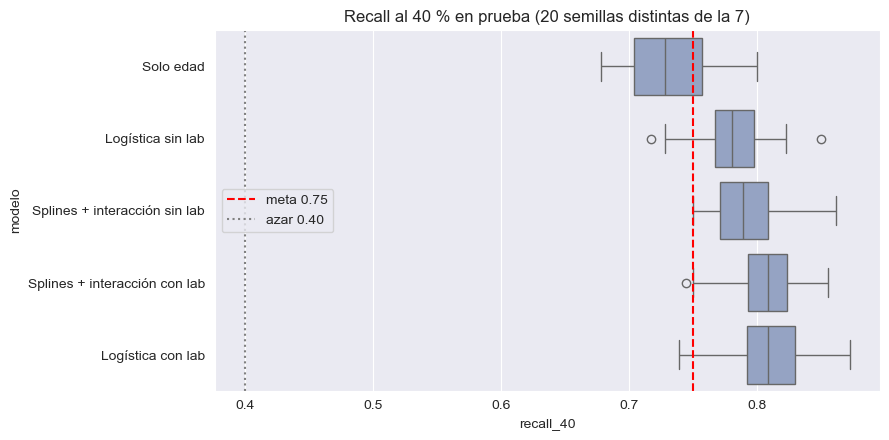

In [23]:
orden = resumen.sort_values("recall_media").index
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=semillas, y="modelo", x="recall_40", order=orden, color="#8DA0CB", ax=ax)
ax.axvline(0.75, color="red", ls="--", label="meta 0.75")
ax.axvline(0.40, color="gray", ls=":", label="azar 0.40")
ax.set_title("Recall al 40 % en prueba (20 semillas distintas de la 7)")
ax.legend(loc="center left")
plt.tight_layout()
plt.savefig(FIG_DIR / "supuestos_escenarios_recall_semillas.png", dpi=150)
plt.show()

In [24]:
# comparaciones de a pares (misma semilla = misma partición)
pivote = semillas.pivot(index="semilla", columns="modelo", values="recall_40")
comparaciones = [("Logística con lab", "Logística sin lab"),
                 ("Splines + interacción con lab", "Splines + interacción sin lab"),
                 ("Logística sin lab", "Solo edad"),
                 ("Logística con lab", "Solo edad"),
                 ("Splines + interacción sin lab", "Logística sin lab"),
                 ("Splines + interacción con lab", "Logística con lab")]
filas = []
for a, b in comparaciones:
    d = pivote[a] - pivote[b]
    filas.append({"comparación": f"{a} menos {b}", "diferencia_media": round(d.mean(), 4),
                  "semillas_donde_gana": int((d > 0).sum()), "p_wilcoxon": round(stats.wilcoxon(d).pvalue, 4)})
pd.DataFrame(filas).set_index("comparación")

,diferencia_media,semillas_donde_gana,p_wilcoxon
comparación,,,
Logística con lab menos Logística sin lab,0.0247,19,0.0001
Splines + interacción con lab menos Splines + interacción sin lab,0.0136,15,0.0087
Logística sin lab menos Solo edad,0.0503,18,0.0002
Logística con lab menos Solo edad,0.0750,20,0.0001
Splines + interacción sin lab menos Logística sin lab,0.0100,15,0.0092
Splines + interacción con lab menos Logística con lab,-0.0011,10,0.5578
